# Q3: Adult Income - EDA, baseline, AutoML (TPOT), save model
Pipeline: EDA -> preprocessing -> Logistic Regression baseline -> TPOT -> compare -> save -> metrics.json
The saved model + metrics.json are used by api.py (FastAPI) and app.py (Streamlit).

In [1]:
import json, time, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.inspection import permutation_importance

(32561, 15) 
Missing per column:
 workclass         1836
occupation        1843
native.country     583
dtype: int64
income
<=50K    0.75919
>50K     0.24081
Name: proportion, dtype: float64


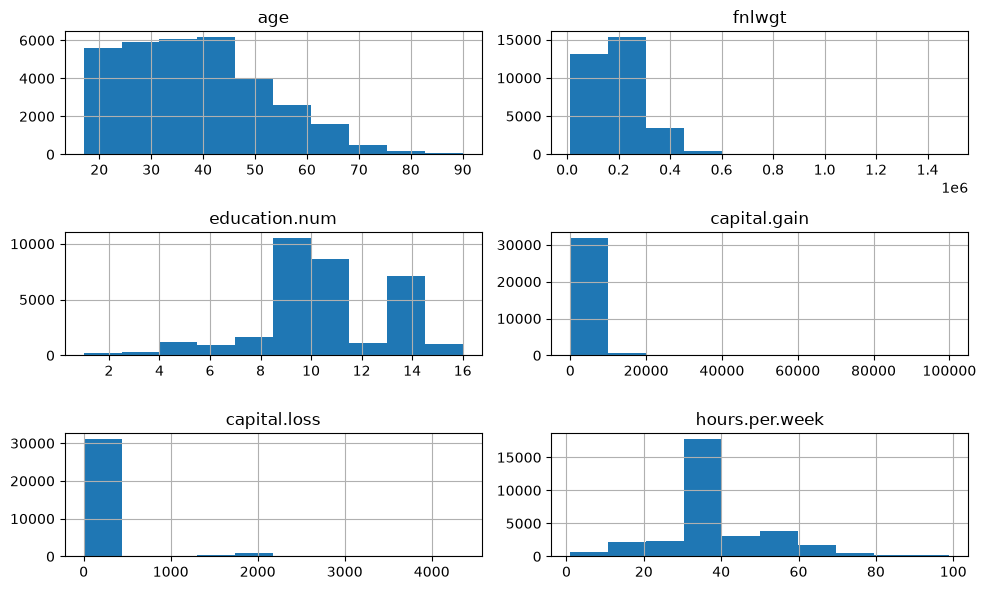

                 age  fnlwgt  education.num  capital.gain  capital.loss  \
age             1.00   -0.08           0.04          0.08          0.06   
fnlwgt         -0.08    1.00          -0.04          0.00         -0.01   
education.num   0.04   -0.04           1.00          0.12          0.08   
capital.gain    0.08    0.00           0.12          1.00         -0.03   
capital.loss    0.06   -0.01           0.08         -0.03          1.00   
hours.per.week  0.07   -0.02           0.15          0.08          0.05   

                hours.per.week  
age                       0.07  
fnlwgt                   -0.02  
education.num             0.15  
capital.gain              0.08  
capital.loss              0.05  
hours.per.week            1.00  


In [2]:
df = pd.read_csv("../ASSIGNMENT03/adult.csv").replace("?", np.nan)
print(df.shape, "\nMissing per column:\n", df.isna().sum()[lambda s: s > 0])
print(df["income"].value_counts(normalize=True))            # ~76% <=50K -> imbalanced
df.hist(figsize=(10, 6)); plt.tight_layout(); plt.savefig("results/q3_distributions.png"); plt.show()
print(df.select_dtypes("number").corr().round(2))

In [3]:
df["net.capital"] = df["capital.gain"] - df["capital.loss"]
y = (df["income"].str.strip() == ">50K").astype(int)
X = df.drop(columns="income")
num = X.select_dtypes("number").columns.tolist()
cat = [c for c in X.columns if c not in num]
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [4]:
t = time.time()
base = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))]).fit(Xtr, ytr)
base_time = time.time() - t
base_acc, base_f1 = accuracy_score(yte, base.predict(Xte)), f1_score(yte, base.predict(Xte))
print(f"Baseline  acc={base_acc:.4f} f1={base_f1:.4f} time={base_time:.1f}s")

Baseline  acc=0.8528 f1=0.6624 time=2.2s


In [6]:
%pip install -q "setuptools<81"

Note: you may need to restart the kernel to use updated packages.


In [7]:
from tpot import TPOTClassifier
Xtr_p = prep.fit_transform(Xtr)                      # numeric matrix for TPOT
t = time.time()
try:     # TPOT >= 1.0
    tpot = TPOTClassifier(search_space="linear-light", max_time_mins=5, cv=3, n_jobs=4, random_state=42, verbose=1)
except TypeError:   # TPOT 0.x
    tpot = TPOTClassifier(generations=3, population_size=10, max_time_mins=5, cv=3, n_jobs=4, random_state=42, verbosity=2)
tpot.fit(Xtr_p, ytr)
auto_time = time.time() - t
auto = Pipeline([("prep", prep), ("clf", tpot.fitted_pipeline_)])   # raw input -> prediction
auto_acc, auto_f1 = accuracy_score(yte, auto.predict(Xte)), f1_score(yte, auto.predict(Xte))
print(f"TPOT      acc={auto_acc:.4f} f1={auto_f1:.4f} time={auto_time:.1f}s")
print("Best pipeline:", tpot.fitted_pipeline_)

/home/asimo/anaconda3/envs/myenv/lib/python3.13/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Generation: : 0it [00:00, ?it/s]/home/asimo/anaconda3/envs/myenv/lib/python3.13/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/asimo/anaconda3/envs/myenv/lib/python3.13/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30

TPOT      acc=0.8465 f1=0.6549 time=415.3s
Best pipeline: Pipeline(steps=[('normalizer', Normalizer(norm=np.str_('l2'))),
                ('selectpercentile',
                 SelectPercentile(percentile=87.4306730968204)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('featureunion',
                                                 FeatureUnion(transformer_list=[('zerocount',
                                                                                 ZeroCount())])),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('kneighborsclassifier',
       

In [10]:
print(pd.DataFrame({"Model": ["Logistic Regression", "TPOT"], "Accuracy": [base_acc, auto_acc],
                    "F1": [base_f1, auto_f1], "Train time (s)": [base_time, auto_time]}).round(4))
best, best_acc, name = (auto, auto_acc, "TPOT") if auto_acc >= base_acc else (base, base_acc, "Logistic Regression")
joblib.dump(best, "best_adult_income_model.joblib")

                 Model  Accuracy      F1  Train time (s)
0  Logistic Regression    0.8528  0.6624          2.2297
1                 TPOT    0.8465  0.6549        415.2907


['best_adult_income_model.joblib']

In [11]:
sub = Xte.sample(1500, random_state=42)
pi = permutation_importance(best, sub, yte.loc[sub.index], n_repeats=3, random_state=42)
top5 = pd.Series(pi.importances_mean, index=Xte.columns).nlargest(5)
print(top5)
json.dump({"model": name, "accuracy": round(best_acc, 4), "f1": round(float(f1_score(yte, best.predict(Xte))), 4),
           "top5": {k: round(float(v), 4) for k, v in top5.items()}}, open("metrics.json", "w"), indent=2)

marital.status    0.048000
education.num     0.033556
relationship      0.011111
net.capital       0.010667
occupation        0.009333
dtype: float64


**Discussion (fill in from YOUR results):** AutoML searches models/hyperparameters automatically and can gain a
little accuracy, but costs minutes instead of seconds and yields a more complex, less interpretable model;
the baseline is fast, simple and explainable. Class imbalance (~76/24) means F1 matters beside accuracy.